<a href="https://colab.research.google.com/github/Amartyesh/Mars-Lonar-Analog-Research/blob/main/notebooks/Jezero_CRISM_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Phase 7: Jezero CRISM Analysis

!pip -q install spectral rasterio pds4_tools

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Jezero CRISM environment initialized!")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
NumPy: 2.4.6
Pandas: 2.2.3
Jezero CRISM environment initialized!


In [ ]:
import requests

url = "https://oderest.rsl.wustl.edu/live2/"

params = {
    "query": "product",
    "results": "fp",
    "output": "JSON",
    "limit": 50,
    "target": "mars",
    "ihid": "MRO",
    "iid": "CRISM",
    "pt": "MTRDR",
    "westlon": 76.5,
    "eastlon": 78.5,
    "minlat": 17.5,
    "maxlat": 19.5
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

data = response.json()

products = data["ODEResults"]["Products"]["Product"]

if isinstance(products, dict):
    products = [products]

print("CRISM MTRDR products found:", len(products))

for i, product in enumerate(products, 1):
    print(f"\n{i}. Product ID:", product.get("pdsid"))

    files = product.get("Product_files", {}).get("Product_file", [])
    if isinstance(files, dict):
        files = [files]

    for file in files:
        if file.get("URL", "").lower().endswith((".img", ".lbl")):
            print("   File:", file["URL"])

CRISM MTRDR products found: 32

1. Product ID: hrl000040ff_07_if183j_mtr3
   File: https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brcarj_mtr3.img
   File: https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brcarj_mtr3.lbl
   File: https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brchlj_mtr3.img
   File: https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brchlj_mtr3.lbl
   File: https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brcr2j_mtr3.img
   File: https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brcr2j_mtr3.lbl
  

In [ ]:
import requests

label_url = (
    "https://pds-geosciences.wustl.edu/mro/"
    "mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/"
    "mtrdr/2007/2007_029/hrl000040ff/"
    "hrl000040ff_07_if183j_mtr3.lbl"
)

response = requests.get(label_url, timeout=60)
response.raise_for_status()

label_text = response.text

print(label_text[:12000])

PDS_VERSION_ID                 = PDS3

RECORD_TYPE                    = FIXED_LENGTH
RECORD_BYTES                   = 1820
FILE_RECORDS                   = 367239
LABEL_REVISION_NOTE            = 
    "2012-03-06, H. Taylor, F. Seelos (JHU/APL)
     Initial TER/MTRDR labels for CRISM Data Users' Workshop;
     2014-01-09, G. Romeo, J. Aiello, F. Seelos (JHU/APL)
     Complete TER/MTRDR label set for preliminary PDS review;
     2014-04-08, G. Romeo, J. Aiello, R. Espiritu, F. Seelos (JHU/APL)
     TER/MTRDR label set revisions completed for PDS peer review;
     2014-08-14, G. Romeo, J. Aiello, F. Seelos (JHU/APL)
     PDS peer review TER/MTRDR label set liens retired;"

^ENVI_HEADER                   = "HRL000040FF_07_IF183J_MTR3.HDR"

^IMAGE                         = "HRL000040FF_07_IF183J_MTR3.IMG"

/* Map-Projected Targeted RDR Identification */
DATA_SET_ID                    = "MRO-M-CRISM-5-RDR-MPTARGETED-V1.0"
PRODUCT_ID                     = "HRL000040FF_07_IF183J_MTR3"

/*    

In [ ]:
import requests
from pathlib import Path

base_url = (
    "https://pds-geosciences.wustl.edu/mro/"
    "mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/"
    "mtrdr/2007/2007_029/hrl000040ff/"
)

files_to_get = [
    "HRL000040FF_07_IF183J_MTR3.HDR",
    "HRL000040FF_07_WV183J_MTR3.TAB"
]

data_dir = Path("/content/Jezero_CRISM")
data_dir.mkdir(exist_ok=True)

for filename in files_to_get:
    r = requests.get(base_url + filename, timeout=120)
    r.raise_for_status()

    path = data_dir / filename
    path.write_bytes(r.content)

    print(filename, "| Downloaded:", round(len(r.content)/1024, 2), "KB")

print("\n--- ENVI HEADER ---")
print((data_dir / files_to_get[0]).read_text(errors="ignore")[:2500])

print("\n--- WAVELENGTH FILE ---")
print((data_dir / files_to_get[1]).read_text(errors="ignore")[:1200])

HRL000040FF_07_IF183J_MTR3.HDR | Downloaded: 14.49 KB
HRL000040FF_07_WV183J_MTR3.TAB | Downloaded: 14.33 KB

--- ENVI HEADER ---
ENVI
description = {
  ENVI File, Created [Mon Jul 17 11:07:59 2017]}
samples = 455
lines   = 751
bands   = 489
header offset = 0
file type = ENVI Standard
data type = 4
interleave = bsq
sensor type = Unknown
byte order = 0
map info = {MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E], 1.0000, 1.0000, 4422632.2000, 1109935.5000, 3.6000000000e+01, 3.6000000000e+01, D_Mars_2000_IAU_IAG_custom_sphere_lat15, units=Meters}
projection info = {17, 3394839.8, 15.000000, 0.000000, 0.0, 0.0, D_Mars_2000_IAU_IAG_custom_sphere_lat15, MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E], units=Meters}
coordinate system string = {PROJCS["MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E]",GEOGCS["GCS_Mars_2000_IAU_IAG_custom_sphere_lat15",DATUM["D_Mars_2000_IAU_IAG_custom_sphere_lat15",SPHEROID["Mars_2000_IAU_IAG_custom_sphere_lat15",3394839.813316312,0.0]],PRIMEM["Refer

In [ ]:
import requests
from pathlib import Path
from spectral.io import envi

data_dir = Path("/content/Jezero_CRISM")

img_url = (
    "https://pds-geosciences.wustl.edu/mro/"
    "mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/"
    "mtrdr/2007/2007_029/hrl000040ff/"
    "HRL000040FF_07_IF183J_MTR3.IMG"
)

img_path = data_dir / "HRL000040FF_07_IF183J_MTR3.IMG"

if not img_path.exists():
    with requests.get(img_url, stream=True, timeout=300) as r:
        r.raise_for_status()
        total = 0

        with open(img_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
                if chunk:
                    f.write(chunk)
                    total += len(chunk)
                    print(f"\rDownloaded: {total / (1024**2):.1f} MB", end="")

print("\nImage size:", round(img_path.stat().st_size / (1024**2), 2), "MB")

hdr_path = data_dir / "HRL000040FF_07_IF183J_MTR3.HDR"

crism_img = envi.open(str(hdr_path), str(img_path))
crism_cube = crism_img.open_memmap()

print("CRISM cube shape:", crism_cube.shape)
print("Data type:", crism_cube.dtype)

Downloaded: 637.4 MB
Image size: 637.41 MB
CRISM cube shape: (751, 455, 489)
Data type: float32


In [ ]:
import numpy as np
import pandas as pd

# Extract calibrated wavelengths from ENVI metadata
wavelengths = np.array(
    crism_img.metadata["wavelength"], dtype=float
)

# Read CRISM wavelength table
wv_table = pd.read_csv(
    data_dir / "HRL000040FF_07_WV183J_MTR3.TAB",
    sep=",",
    header=None,
    skipinitialspace=True
)

print("Number of image bands:", crism_cube.shape[2])
print("Number of wavelengths:", len(wavelengths))
print("Wavelength range:", wavelengths.min(), "-", wavelengths.max(), "nm")
print("Wavelength table shape:", wv_table.shape)

# CRISM invalid-data value from ENVI header
ignore_value = 65535.0

# Identify valid spectral bands
valid_bands = np.isfinite(wavelengths)

# Sample the cube without loading the full image into RAM
sample = np.asarray(crism_cube[::10, ::10, :])

valid_data = (
    np.isfinite(sample) &
    (sample != ignore_value)
)

print("\nSample cube shape:", sample.shape)
print("Valid sample measurements:", round(valid_data.mean() * 100, 2), "%")
print("Valid wavelength bands:", valid_bands.sum())

Number of image bands: 489
Number of wavelengths: 489
Wavelength range: 436.13 - 3896.76 nm
Wavelength table shape: (489, 5)

Sample cube shape: (76, 46, 489)
Valid sample measurements: 63.14 %
Valid wavelength bands: 489


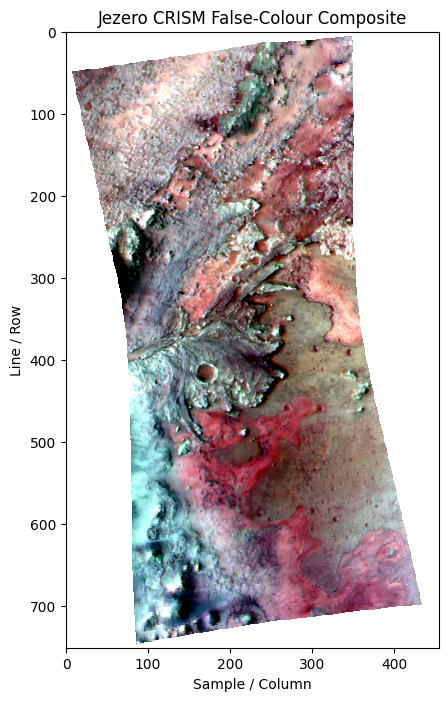

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Default bands in ENVI header are 1-based
rgb_bands = [303, 121, 40]

rgb = np.stack([
    np.asarray(crism_cube[:, :, b])
    for b in rgb_bands
], axis=-1)

# Mask invalid values
rgb[rgb == 65535] = np.nan

# Percentile stretch for display
rgb_display = np.zeros_like(rgb)

for i in range(3):
    band = rgb[:, :, i]
    lo, hi = np.nanpercentile(band, [2, 98])
    rgb_display[:, :, i] = np.clip((band - lo) / (hi - lo), 0, 1)

plt.figure(figsize=(10, 8))
plt.imshow(rgb_display)
plt.title("Jezero CRISM False-Colour Composite")
plt.xlabel("Sample / Column")
plt.ylabel("Line / Row")
plt.show()

Upper_Terrain | Valid pixels: 12000
Central_Crater | Valid pixels: 10000
Lower_Terrain | Valid pixels: 12000


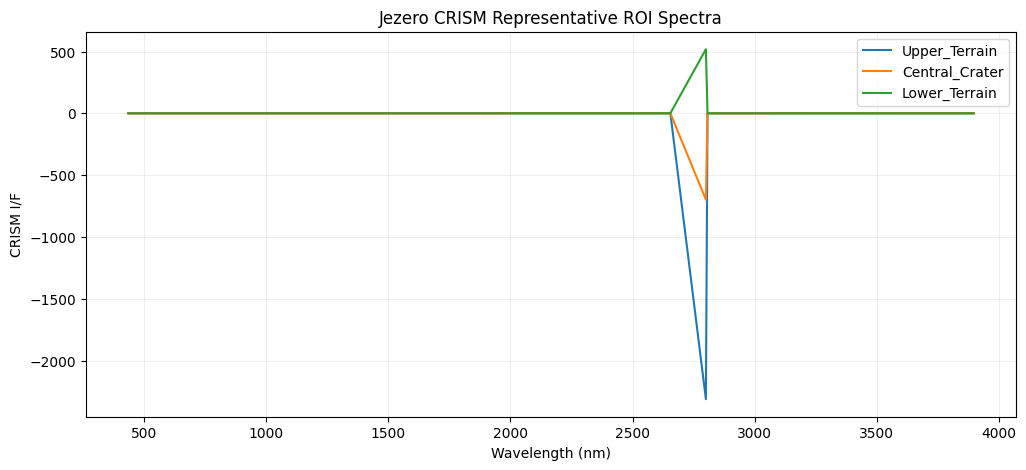

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rois = {
    "Upper_Terrain": (100, 220, 150, 250),
    "Central_Crater": (330, 430, 200, 300),
    "Lower_Terrain": (500, 620, 150, 250)
}

roi_spectra = {}

for name, (r1, r2, c1, c2) in rois.items():

    # .copy() creates a writable array
    region = np.array(
        crism_cube[r1:r2, c1:c2, :],
        dtype=np.float32,
        copy=True
    )

    region[~np.isfinite(region)] = np.nan
    region[region == 65535] = np.nan

    valid_pixels = np.isfinite(region).mean(axis=2) >= 0.70
    spectra = region[valid_pixels]

    if len(spectra) == 0:
        print(name, "- No valid spectra")
        continue

    roi_spectra[name] = np.nanmedian(spectra, axis=0)

    print(name, "| Valid pixels:", len(spectra))

plt.figure(figsize=(12, 5))

for name, spectrum in roi_spectra.items():
    plt.plot(wavelengths, spectrum, label=name)

plt.xlabel("Wavelength (nm)")
plt.ylabel("CRISM I/F")
plt.title("Jezero CRISM Representative ROI Spectra")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [ ]:
import numpy as np

for name, spectrum in roi_spectra.items():
    print(
        name,
        "| Min:", np.nanmin(spectrum),
        "| Max:", np.nanmax(spectrum),
        "| Median:", np.nanmedian(spectrum),
        "| Values > 10:", np.sum(np.abs(spectrum) > 10)
    )

# Inspect actual cube values in the affected wavelength region
bad_band = np.argmin(np.abs(wavelengths - 2800))

print("\nAffected wavelength:", wavelengths[bad_band], "nm")
print("Sample values:", np.asarray(
    crism_cube[100:110, 150:160, bad_band]
).flatten()[:20])

Upper_Terrain | Min: -2312.8047 | Max: 0.31982735 | Median: 0.17491597 | Values > 10: 1
Central_Crater | Min: -698.38257 | Max: 0.33341503 | Median: 0.16423157 | Values > 10: 1
Lower_Terrain | Min: 0.05471547 | Max: 518.4608 | Median: 0.1665305 | Values > 10: 1

Affected wavelength: 2800.35 nm
Sample values: [1037.2144   857.3804   967.00995  987.76154  956.41034  978.5557
 1041.7559  1081.986   1081.986    990.6664  1009.8506   857.1439
 1057.0837  1100.393   1012.2979  1002.43994 1002.43994 1041.7559
 1081.986    990.6664 ]


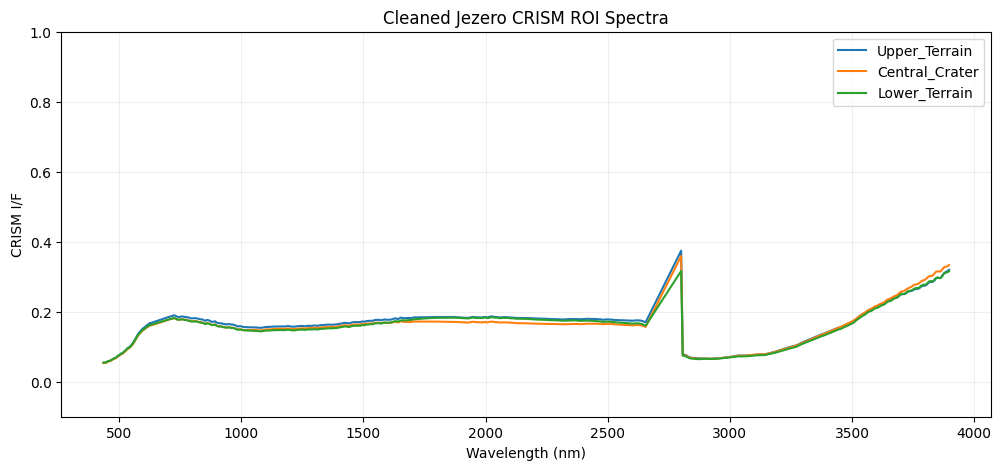

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

roi_spectra_clean = {}

for name, (r1, r2, c1, c2) in rois.items():

    region = np.array(
        crism_cube[r1:r2, c1:c2, :],
        dtype=np.float32,
        copy=True
    )

    # Mask invalid and extreme I/F measurements
    region[
        (~np.isfinite(region)) |
        (region == 65535) |
        (region < -5) |
        (region > 5)
    ] = np.nan

    valid_pixels = np.isfinite(region).mean(axis=2) >= 0.70
    spectra = region[valid_pixels]

    roi_spectra_clean[name] = np.nanmedian(spectra, axis=0)

plt.figure(figsize=(12, 5))

for name, spectrum in roi_spectra_clean.items():
    plt.plot(wavelengths, spectrum, label=name)

plt.xlabel("Wavelength (nm)")
plt.ylabel("CRISM I/F")
plt.title("Cleaned Jezero CRISM ROI Spectra")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [ ]:
import requests
from pathlib import Path

item_id = "586e8c88e4b0f5ce109fccae"

api_url = f"https://www.sciencebase.gov/catalog/item/{item_id}?format=json"

response = requests.get(api_url, timeout=60)
response.raise_for_status()
item = response.json()

target = "ASCIIdata_splib07b_cvCRISMjMTR3.zip"

print("Dataset:", item.get("title"))

matches = [
    f for f in item.get("files", [])
    if target.lower() in f.get("name", "").lower()
]

print("Matching archives:", len(matches))

for f in matches:
    print("File:", f.get("name"))
    print("Download URL:", f.get("url"))
    print("Download URI:", f.get("downloadUri"))

Dataset: Spectra of materials in ASCII format
Matching archives: 1
File: ASCIIdata_splib07b_cvCRISMjMTR3.zip
Download URL: https://www.sciencebase.gov/catalog/file/get/586e8c88e4b0f5ce109fccae?f=__disk__85%2Fbc%2F60%2F85bc6083e59987f5c2b7acdc568c3c0e80903034
Download URI: https://www.sciencebase.gov/catalog/file/get/586e8c88e4b0f5ce109fccae?f=__disk__85%2Fbc%2F60%2F85bc6083e59987f5c2b7acdc568c3c0e80903034


In [ ]:
import requests
import zipfile
from pathlib import Path

data_dir = Path("/content/Jezero_CRISM")
zip_path = data_dir / "CRISM_USGS_References.zip"

url = (
    "https://www.sciencebase.gov/catalog/file/get/"
    "586e8c88e4b0f5ce109fccae"
    "?f=__disk__85%2Fbc%2F60%2F85bc6083e59987f5c2b7acdc568c3c0e80903034"
)

if not zip_path.exists():
    r = requests.get(url, timeout=180)
    r.raise_for_status()
    zip_path.write_bytes(r.content)

print("Downloaded:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

extract_dir = data_dir / "CRISM_References"
extract_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)
    files = z.namelist()

print("Extracted files:", len(files))

for f in files[:15]:
    print(f)

Downloaded: 6.01 MB
Extracted files: 3148
ASCIIdata_splib07b_cvCRISMjMTR3/
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Alizarin_crimson_(dk)_GDS780_ASDFRa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Aluminum_brushed_293K_ASDFRa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Ammonium_Chloride_GDS77_BECKa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Asphalt_GDS376_Blck_Road_old_ASDFRa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Asphalt_Shingle_GDS366_Tan_ASDFRa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Asphalt_Shingle_GDS367_DkGry_ASDFRa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Asphalt_Shingle_GDS368_Lgray_ASDFRa_AREF.txt
ASCIIdata_splib07b_cvCRISMjMTR3/ChapterA_ArtificialMaterials/s07CRSMj_Asp

In [ ]:
from pathlib import Path

ref_dir = Path("/content/Jezero_CRISM/CRISM_References")

mineral_terms = [
    "nontronite",
    "montmorillonite",
    "smectite",
    "hematite",
    "goethite",
    "calcite",
    "carbonate",
    "augite",
    "diopside",
    "plagioclase"
]

reference_files = [
    p for p in ref_dir.rglob("*")
    if p.is_file()
    and any(term in p.name.lower() for term in mineral_terms)
]

print("Relevant reference files found:", len(reference_files))

for p in reference_files[:40]:
    print(p.name)

Relevant reference files found: 197
errorbars_for_s07CRSMj_Augite_NMNH120049_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite_SAz-1_BECKb_AREF.txt
errorbars_for_s07CRSMj_Hematite_GDS69.f_10-20um_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite_CM27_BECKb_AREF.txt
errorbars_for_s07CRSMj_Goethite_WS222_Medium_Gr._BECKa_AREF.txt
errorbars_for_s07CRSMj_Albite_HS143.3B_Plagioclase_BECKc_AREF.txt
errorbars_for_s07CRSMj_Hematite_Coatd_Qtzt_BR93-25A_BECKa_AREF.txt
errorbars_for_s07CRSMj_Calcite_CO2004_BECKb_AREF.txt
errorbars_for_s07CRSMj_Goethite_WS220_BECKc_AREF.txt
errorbars_for_s07CRSMj_Calcite.80wt+Kaol_CM9_GDS213_ASDNGa_AREF.txt
errorbars_for_s07CRSMj_Goethite_HS36.3_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite_SWy-1_BECKb_AREF.txt
errorbars_for_s07CRSMj_Augite_WS588_Pyroxene_BECKb_AREF.txt
errorbars_for_s07CRSMj_Hematite_GDS69.d_30-45um_BECKb_AREF.txt
errorbars_for_s07CRSMj_Augite_WS592_Pyroxene_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite+Illite_CM42_BECKb_A

In [ ]:
print("Reference spectra found:", len(reference_files))

for p in reference_files[:25]:
    print(p.name)

Reference spectra found: 197
errorbars_for_s07CRSMj_Augite_NMNH120049_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite_SAz-1_BECKb_AREF.txt
errorbars_for_s07CRSMj_Hematite_GDS69.f_10-20um_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite_CM27_BECKb_AREF.txt
errorbars_for_s07CRSMj_Goethite_WS222_Medium_Gr._BECKa_AREF.txt
errorbars_for_s07CRSMj_Albite_HS143.3B_Plagioclase_BECKc_AREF.txt
errorbars_for_s07CRSMj_Hematite_Coatd_Qtzt_BR93-25A_BECKa_AREF.txt
errorbars_for_s07CRSMj_Calcite_CO2004_BECKb_AREF.txt
errorbars_for_s07CRSMj_Goethite_WS220_BECKc_AREF.txt
errorbars_for_s07CRSMj_Calcite.80wt+Kaol_CM9_GDS213_ASDNGa_AREF.txt
errorbars_for_s07CRSMj_Goethite_HS36.3_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite_SWy-1_BECKb_AREF.txt
errorbars_for_s07CRSMj_Augite_WS588_Pyroxene_BECKb_AREF.txt
errorbars_for_s07CRSMj_Hematite_GDS69.d_30-45um_BECKb_AREF.txt
errorbars_for_s07CRSMj_Augite_WS592_Pyroxene_BECKb_AREF.txt
errorbars_for_s07CRSMj_Montmorillonite+Illite_CM42_BECKb_AREF.txt

In [ ]:
import numpy as np
import pandas as pd

results = []

for roi_name, sample_spectrum in roi_spectra_clean.items():

    best_angle = np.inf
    best_file = None

    for path in reference_files:

        try:
            data = np.loadtxt(path, comments="#")

            if data.ndim != 2 or data.shape[1] < 2:
                continue

            ref_wavelength = data[:, 0]
            ref_reflectance = data[:, 1]

            valid = (
                np.isfinite(ref_wavelength) &
                np.isfinite(ref_reflectance)
            )

            ref_wavelength = ref_wavelength[valid]
            ref_reflectance = ref_reflectance[valid]

            if len(ref_wavelength) < 10:
                continue

            # Interpolate reference to CRISM wavelengths
            reference = np.interp(
                wavelengths,
                ref_wavelength,
                ref_reflectance,
                left=np.nan,
                right=np.nan
            )

            # Use common valid wavelengths
            mask = (
                np.isfinite(sample_spectrum) &
                np.isfinite(reference) &
                (sample_spectrum > 0) &
                (reference > 0)
            )

            if mask.sum() < 50:
                continue

            a = sample_spectrum[mask]
            b = reference[mask]

            cosine = np.dot(a, b) / (
                np.linalg.norm(a) * np.linalg.norm(b)
            )

            angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

            if angle < best_angle:
                best_angle = angle
                best_file = path.name

        except Exception:
            continue

    results.append({
        "ROI": roi_name,
        "Best_Reference": best_file,
        "SAM_Angle_Degrees": best_angle
    })

sam_results = pd.DataFrame(results)
print(sam_results.to_string(index=False))

           ROI Best_Reference  SAM_Angle_Degrees
 Upper_Terrain           None                inf
Central_Crater           None                inf
 Lower_Terrain           None                inf


In [ ]:
# Exclude error-bar files; retain actual reference spectra
main_reference_files = [
    p for p in reference_files
    if not p.name.lower().startswith("errorbars_for_")
]

print("Actual reference files:", len(main_reference_files))

for p in main_reference_files[:10]:
    print(p.name)

Actual reference files: 143
s07CRSMj_Diopside_HS317.1B_(Cr)Pyx_ASDFRc_AREF.txt
s07CRSMj_Goethite_WS220_NIC4cd_RREF.txt
s07CRSMj_Montmorillonite_CM20_NIC4bc_RREF.txt
s07CRSMj_Diopside_HS15.8_pyroxene_ASDFRc_AREF.txt
s07CRSMj_Hematite_GDS69.c_60-104um_NIC4bb_RREF.txt
s07CRSMj_Albite_HS143.3B_Plagioclase_BECKc_AREF.txt
s07CRSMj_Hematite_GDS69.e_20-30um_BECKb_AREF.txt
s07CRSMj_Hematite_HS45.3_ASDFRb_AREF.txt
s07CRSMj_Albite_HS324.3B_Plagioclase_ASDFRc_AREF.txt
s07CRSMj_Goethite_GDS134_NIC4bbu_RREF.txt


In [ ]:
# Inspect one actual reference spectrum
for p in main_reference_files[:2]:
    print("\nFILE:", p.name)
    with open(p, "r", errors="ignore") as f:
        for _ in range(12):
            line = f.readline()
            if not line:
                break
            print(line.rstrip())


FILE: s07CRSMj_Diopside_HS317.1B_(Cr)Pyx_ASDFRc_AREF.txt
s07CRSMj Record=1580: Diopside HS317.1B (Cr)Pyx    ASDFRc AREF
 5.4797173e-001
 5.4881972e-001
 5.4970640e-001
 5.5057693e-001
 5.5145532e-001
 5.5235797e-001
 5.5324823e-001
 5.5422145e-001
 5.5518979e-001
 5.5610090e-001
 5.5694735e-001

FILE: s07CRSMj_Goethite_WS220_NIC4cd_RREF.txt
s07CRSMj Record=1982: Goethite WS220               NIC4cd RREF
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034
-1.2300000e+034


In [ ]:
# Check AREF reference spectra
aref_files = [
    p for p in main_reference_files
    if "_AREF" in p.name
]

print("AREF files:", len(aref_files))
print("CRISM wavelength bands:", len(wavelengths))

for p in aref_files[:5]:
    values = np.loadtxt(p, skiprows=1)
    valid = np.isfinite(values) & (np.abs(values) < 1e10)

    print(
        p.name,
        "| Bands:", len(values),
        "| Valid:", valid.sum(),
        "| Range:", (
            round(values[valid].min(), 4),
            round(values[valid].max(), 4)
        ) if valid.any() else "No valid values"
    )

AREF files: 111
CRISM wavelength bands: 489
s07CRSMj_Diopside_HS317.1B_(Cr)Pyx_ASDFRc_AREF.txt | Bands: 489 | Valid: 299 | Range: (np.float64(0.4674), np.float64(0.5604))
s07CRSMj_Diopside_HS15.8_pyroxene_ASDFRc_AREF.txt | Bands: 489 | Valid: 299 | Range: (np.float64(0.1516), np.float64(0.2763))
s07CRSMj_Albite_HS143.3B_Plagioclase_BECKc_AREF.txt | Bands: 489 | Valid: 350 | Range: (np.float64(0.3136), np.float64(0.9102))
s07CRSMj_Hematite_GDS69.e_20-30um_BECKb_AREF.txt | Bands: 489 | Valid: 350 | Range: (np.float64(0.0737), np.float64(0.3499))
s07CRSMj_Hematite_HS45.3_ASDFRb_AREF.txt | Bands: 489 | Valid: 299 | Range: (np.float64(0.0647), np.float64(0.1771))


In [ ]:
import numpy as np
import pandas as pd

results = []

# Use the mineral diagnostic region; avoid long-wavelength noisy region
wave_mask = (wavelengths >= 450) & (wavelengths <= 2600)

for roi_name, sample_spectrum in roi_spectra_clean.items():

    sample_spectrum = np.asarray(sample_spectrum, dtype=float)

    for path in aref_files:

        ref = np.loadtxt(path, skiprows=1)

        # Common valid bands for this ROI and reference
        mask = (
            wave_mask &
            np.isfinite(sample_spectrum) &
            np.isfinite(ref) &
            (np.abs(ref) < 1e10)
        )

        if mask.sum() < 100:
            continue

        a = sample_spectrum[mask]
        b = ref[mask]

        norm_a = np.linalg.norm(a)
        norm_b = np.linalg.norm(b)

        if norm_a == 0 or norm_b == 0:
            continue

        cosine = np.dot(a, b) / (norm_a * norm_b)
        angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

        mineral = path.name.replace("s07CRSMj_", "").replace("_AREF.txt", "")

        results.append({
            "ROI": roi_name,
            "Reference": mineral,
            "SAM_Angle": angle,
            "Common_Bands": mask.sum()
        })

sam_results = pd.DataFrame(results)

if not sam_results.empty:
    print("Valid comparisons:", len(sam_results))

    for roi in roi_spectra_clean:
        print(f"\n{roi} — Top 5 matches")
        display(
            sam_results[sam_results["ROI"] == roi]
            .sort_values("SAM_Angle")
            .head(5)
            .round(3)
        )
else:
    print("No valid comparisons. Check ROI spectra.")

Valid comparisons: 333

Upper_Terrain — Top 5 matches


,ROI,Reference,SAM_Angle,Common_Bands
91,Upper_Terrain,Goethite0.02+Quartz_GDS240_BECKa,4.496,311
110,Upper_Terrain,Goethite_Thin_Film_WS222_BECKa,6.105,175
67,Upper_Terrain,Diopside_HS15.1B_pyroxene_ASDFRc,6.552,296
31,Upper_Terrain,Albite_HS143.1B_Plagioclase_ASDFRb,6.752,296
20,Upper_Terrain,Albite_HS66.1B_Plagioclase_ASDFRc,6.784,296



Central_Crater — Top 5 matches


,ROI,Reference,SAM_Angle,Common_Bands
202,Central_Crater,Goethite0.02+Quartz_GDS240_BECKa,4.574,311
221,Central_Crater,Goethite_Thin_Film_WS222_BECKa,6.020,175
142,Central_Crater,Albite_HS143.1B_Plagioclase_ASDFRb,6.349,296
174,Central_Crater,Albite_HS143.4B_Plagioclase_ASDFRc,6.366,296
131,Central_Crater,Albite_HS66.1B_Plagioclase_ASDFRc,6.366,296



Lower_Terrain — Top 5 matches


,ROI,Reference,SAM_Angle,Common_Bands
313,Lower_Terrain,Goethite0.02+Quartz_GDS240_BECKa,4.836,311
289,Lower_Terrain,Diopside_HS15.1B_pyroxene_ASDFRc,6.252,296
332,Lower_Terrain,Goethite_Thin_Film_WS222_BECKa,6.741,175
253,Lower_Terrain,Albite_HS143.1B_Plagioclase_ASDFRb,7.041,296
242,Lower_Terrain,Albite_HS66.1B_Plagioclase_ASDFRc,7.097,296


Mapping candidates:
Goethite0.02+Quartz_GDS240_BECKa
Goethite_Thin_Film_WS222_BECKa
Diopside_HS15.1B_pyroxene_ASDFRc
Albite_HS143.1B_Plagioclase_ASDFRb
Albite_HS143.4B_Plagioclase_ASDFRc


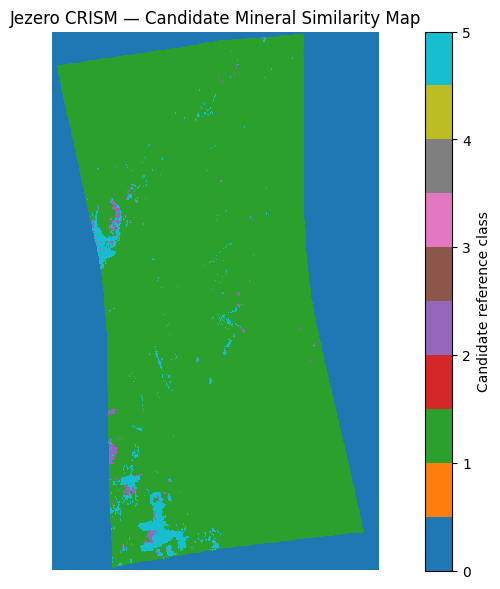


Class legend:
1 = Goethite0.02+Quartz_GDS240_BECKa
2 = Goethite_Thin_Film_WS222_BECKa
3 = Diopside_HS15.1B_pyroxene_ASDFRc
4 = Albite_HS143.1B_Plagioclase_ASDFRb
5 = Albite_HS143.4B_Plagioclase_ASDFRc
Mapped pixels: 220978


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Select five distinct best-matching reference spectra
top_refs = (
    sam_results.sort_values("SAM_Angle")
    .drop_duplicates("Reference")
    .head(5)["Reference"].tolist()
)

ref_lookup = {
    p.name.replace("s07CRSMj_", "").replace("_AREF.txt", ""): p
    for p in aref_files
}

selected_refs = [(name, ref_lookup[name]) for name in top_refs if name in ref_lookup]

print("Mapping candidates:")
for name, _ in selected_refs:
    print(name)

# Prepare output maps
best_angle = np.full(crism_cube.shape[:2], np.inf, dtype=np.float32)
best_class = np.zeros(crism_cube.shape[:2], dtype=np.uint8)

for class_id, (name, path) in enumerate(selected_refs, start=1):

    ref = np.loadtxt(path, skiprows=1)[wave_mask]
    ref_valid = np.isfinite(ref) & (np.abs(ref) < 1e10)

    for r in range(0, crism_cube.shape[0], 25):

        data = np.array(
            crism_cube[r:r+25, :, :][:, :, wave_mask],
            dtype=np.float32,
            copy=True
        )

        valid = (
            np.isfinite(data) &
            (np.abs(data) <= 5) &
            ref_valid[None, None, :]
        )

        x = np.where(valid, data, 0)
        y = np.where(valid, ref[None, None, :], 0)

        dot = np.sum(x * y, axis=2)
        nx = np.sqrt(np.sum(x**2, axis=2))
        ny = np.sqrt(np.sum(y**2, axis=2))
        count = valid.sum(axis=2)

        cosine = dot / np.maximum(nx * ny, 1e-12)
        angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

        angle[(count < 100) | (nx == 0) | (ny == 0)] = np.inf

        update = angle < best_angle[r:r+25, :]
        best_angle[r:r+25, :][update] = angle[update]
        best_class[r:r+25, :][update] = class_id

# Display map
plt.figure(figsize=(12, 7))
plt.imshow(best_class, cmap="tab10", interpolation="nearest")
plt.colorbar(label="Candidate reference class")
plt.title("Jezero CRISM — Candidate Mineral Similarity Map")
plt.axis("off")
plt.show()

print("\nClass legend:")
for i, (name, _) in enumerate(selected_refs, start=1):
    print(i, "=", name)

print("Mapped pixels:", np.isfinite(best_angle).sum())

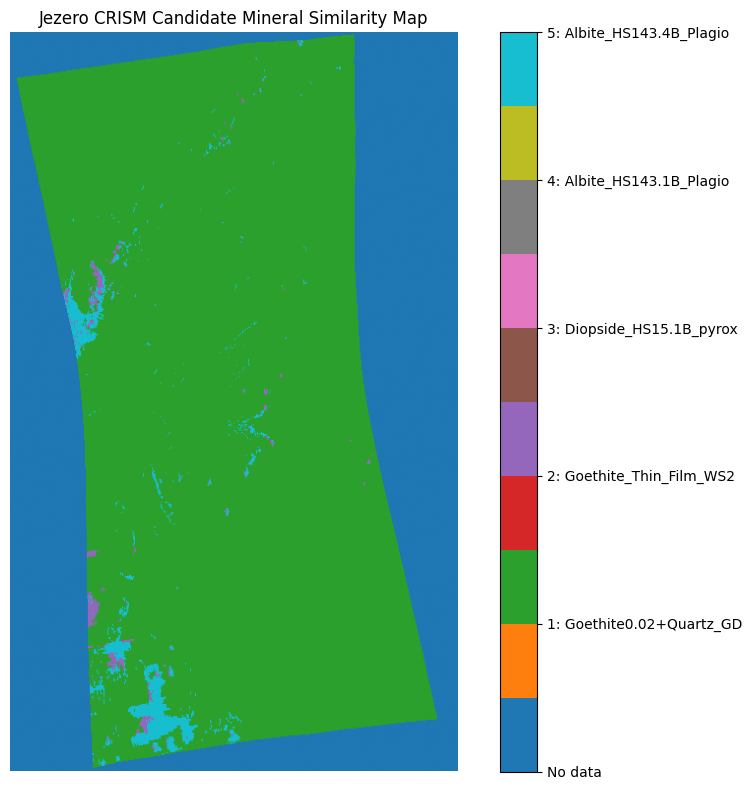

FINAL EXPORT COMPLETED


,Class_ID,Reference,Pixel_Count,Percentage_of_Mapped_Pixels
0,1,Goethite0.02+Quartz_GDS240_BECKa,213974,96.83
1,2,Goethite_Thin_Film_WS222_BECKa,1440,0.65
2,3,Diopside_HS15.1B_pyroxene_ASDFRc,0,0.00
3,4,Albite_HS143.1B_Plagioclase_ASDFRb,0,0.00
4,5,Albite_HS143.4B_Plagioclase_ASDFRc,5564,2.52


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import zipfile
from pathlib import Path
from google.colab import files

out_dir = Path("/content/Jezero_Final_Results")
out_dir.mkdir(exist_ok=True)

# 1. Export classification map
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(best_class, cmap="tab10", vmin=0, vmax=5)
cbar = plt.colorbar(im, ax=ax, ticks=range(6))
cbar.ax.set_yticklabels(["No data"] + [
    f"{i}: {name[:22]}" for i, (name, _) in enumerate(selected_refs, 1)
])

ax.set_title("Jezero CRISM Candidate Mineral Similarity Map")
ax.axis("off")
plt.tight_layout()
plt.savefig(out_dir / "Jezero_Mineral_Map.png", dpi=300)
plt.show()

# 2. Export class pixel counts
class_counts = pd.DataFrame({
    "Class_ID": range(1, len(selected_refs) + 1),
    "Reference": [name for name, _ in selected_refs],
    "Pixel_Count": [
        int(np.sum(best_class == i))
        for i in range(1, len(selected_refs) + 1)
    ]
})
class_counts["Percentage_of_Mapped_Pixels"] = (
    class_counts["Pixel_Count"] / max(1, np.sum(best_class > 0)) * 100
)
class_counts.to_csv(out_dir / "Jezero_Class_Summary.csv", index=False)

# 3. Export ROI matching results
sam_results.to_csv(out_dir / "Jezero_ROI_SAM_Results.csv", index=False)

# 4. Save classification arrays
np.savez_compressed(
    out_dir / "Jezero_CRISM_Classification.npz",
    best_class=best_class,
    best_angle=best_angle
)

# 5. Package everything
zip_path = "/content/Jezero_Final_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in out_dir.iterdir():
        z.write(p, arcname=p.name)

print("FINAL EXPORT COMPLETED")
display(class_counts.round(2))
files.download(zip_path)

**Phase 8- Jezero-SAM similarity matrix**

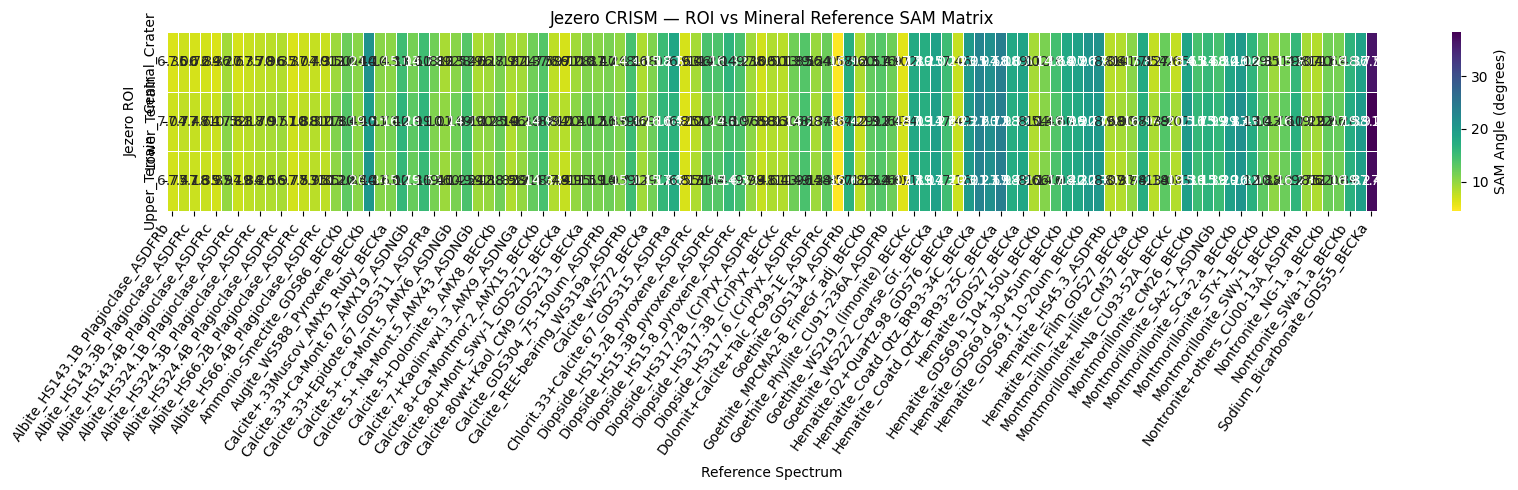

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# ROI × reference spectral angle matrix
jezero_matrix = sam_results.pivot_table(
    index="ROI",
    columns="Reference",
    values="SAM_Angle",
    aggfunc="min"
)

plt.figure(figsize=(17, 5))
sns.heatmap(
    jezero_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis_r",
    linewidths=0.5,
    cbar_kws={"label": "SAM Angle (degrees)"}
)

plt.title("Jezero CRISM — ROI vs Mineral Reference SAM Matrix")
plt.xlabel("Reference Spectrum")
plt.ylabel("Jezero ROI")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.savefig("Jezero_SAM_Similarity_Matrix.png", dpi=300)
plt.show()

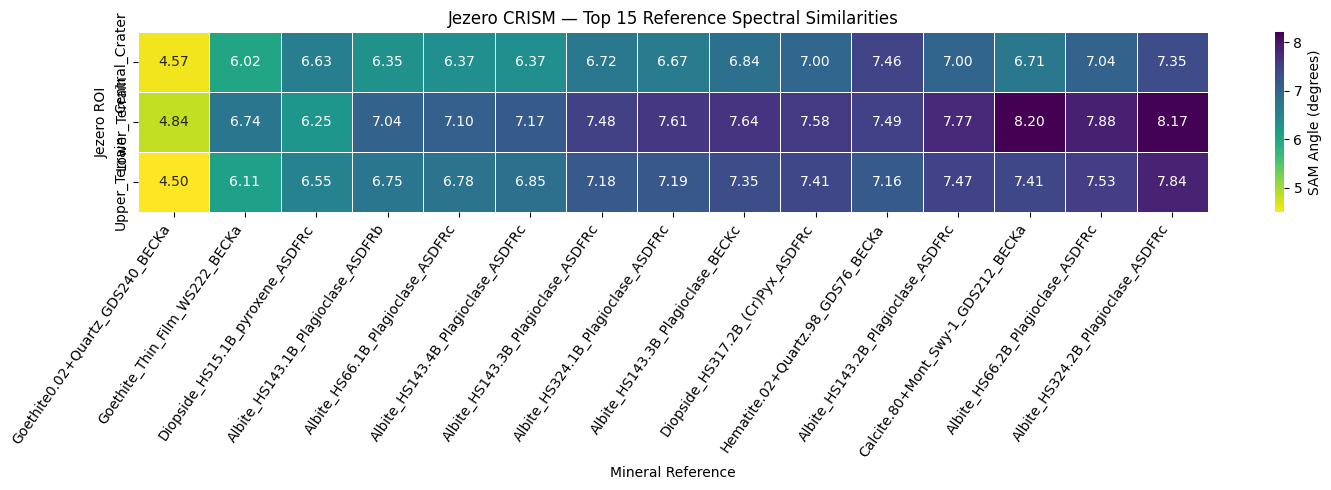

In [ ]:
# Select 15 best references based on mean SAM angle across ROIs
top15 = jezero_matrix.mean(axis=0).nsmallest(15).index

final_jezero_matrix = jezero_matrix[top15]

plt.figure(figsize=(15, 5))

sns.heatmap(
    final_jezero_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis_r",
    linewidths=0.5,
    cbar_kws={"label": "SAM Angle (degrees)"}
)

plt.title("Jezero CRISM — Top 15 Reference Spectral Similarities")
plt.xlabel("Mineral Reference")
plt.ylabel("Jezero ROI")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()

plt.savefig("Jezero_Final_SAM_Matrix.png", dpi=300)
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Lonar_Median_Spectrum.csv to Lonar_Median_Spectrum.csv


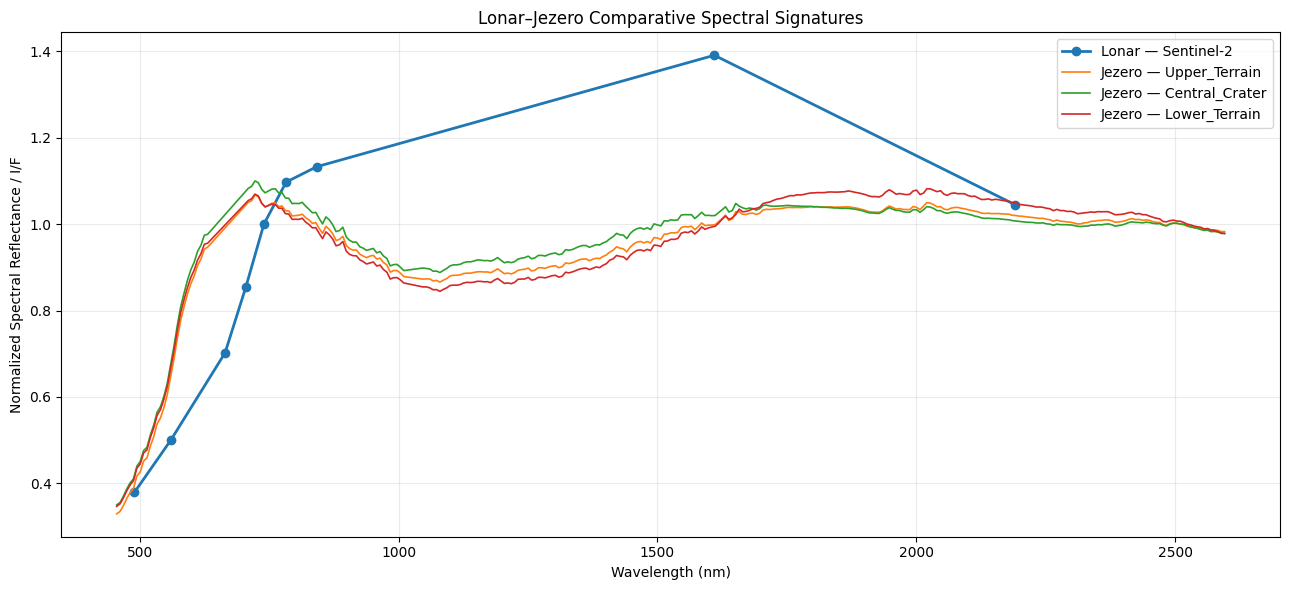

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Lonar spectrum
lonar_df = pd.read_csv("Lonar_Median_Spectrum.csv")

lonar_wl = lonar_df["Wavelength_nm"].values
lonar_ref = lonar_df["Lonar_Median_Reflectance"].values

# Prepare Lonar normalized spectral shape
lonar_norm = lonar_ref / np.nanmedian(lonar_ref)

# Prepare Jezero ROI spectra
plt.figure(figsize=(13, 6))

plt.plot(
    lonar_wl,
    lonar_norm,
    "o-",
    linewidth=2,
    label="Lonar — Sentinel-2"
)

for name, spectrum in roi_spectra_clean.items():

    spectrum = np.asarray(spectrum, dtype=float)

    mask = (
        np.isfinite(spectrum) &
        (spectrum > 0) &
        (wavelengths >= 450) &
        (wavelengths <= 2600)
    )

    if mask.sum() < 10:
        continue

    normalized = spectrum[mask] / np.nanmedian(spectrum[mask])

    plt.plot(
        wavelengths[mask],
        normalized,
        linewidth=1.2,
        label=f"Jezero — {name}"
    )

plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalized Spectral Reflectance / I/F")
plt.title("Lonar–Jezero Comparative Spectral Signatures")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("Lonar_Jezero_Comparative_Spectra.png", dpi=300)
plt.show()

In [ ]:
print("LONAR MEDIAN SPECTRUM")
print(lonar_df.round(4).to_string(index=False))

print("\nJEZERO ROI MEDIAN SPECTRA")
for name, spectrum in roi_spectra_clean.items():
    print("\n", name)
    print("Median:", np.round(spectrum, 4))

print("\nCOMPARATIVE PLOT CHECK")
print("Lonar wavelengths:", len(lonar_wl))
print("Jezero wavelengths:", len(wavelengths))

LONAR MEDIAN SPECTRUM
 Wavelength_nm  Lonar_Median_Reflectance    Q25    Q75
           490                    0.0766 0.0654 0.0917
           560                    0.1009 0.0861 0.1202
           665                    0.1418 0.1208 0.1656
           705                    0.1724 0.1515 0.1944
           740                    0.2020 0.1820 0.2235
           783                    0.2216 0.1997 0.2445
           842                    0.2288 0.2002 0.2558
          1610                    0.2809 0.2403 0.3136
          2190                    0.2111 0.1850 0.2292

JEZERO ROI MEDIAN SPECTRA

 Upper_Terrain
Median: [0.0539 0.0541 0.056  0.0585 0.0595 0.0619 0.0649 0.0673 0.069  0.0741
 0.0758 0.0803 0.0815 0.0864 0.0903 0.0955 0.098  0.1021 0.1074 0.1149
 0.1222 0.1307 0.1381 0.1438 0.1489 0.1531 0.1563 0.1607 0.1633 0.1673
 0.1682 0.1866 0.1872 0.1897 0.1889 0.1862 0.1848 0.1854 0.1863 0.1864
 0.1849 0.1851 0.1832 0.1831 0.181  0.1811 0.1813 0.1817 0.1803 0.1794
 0.178  0.1783 0.1759 

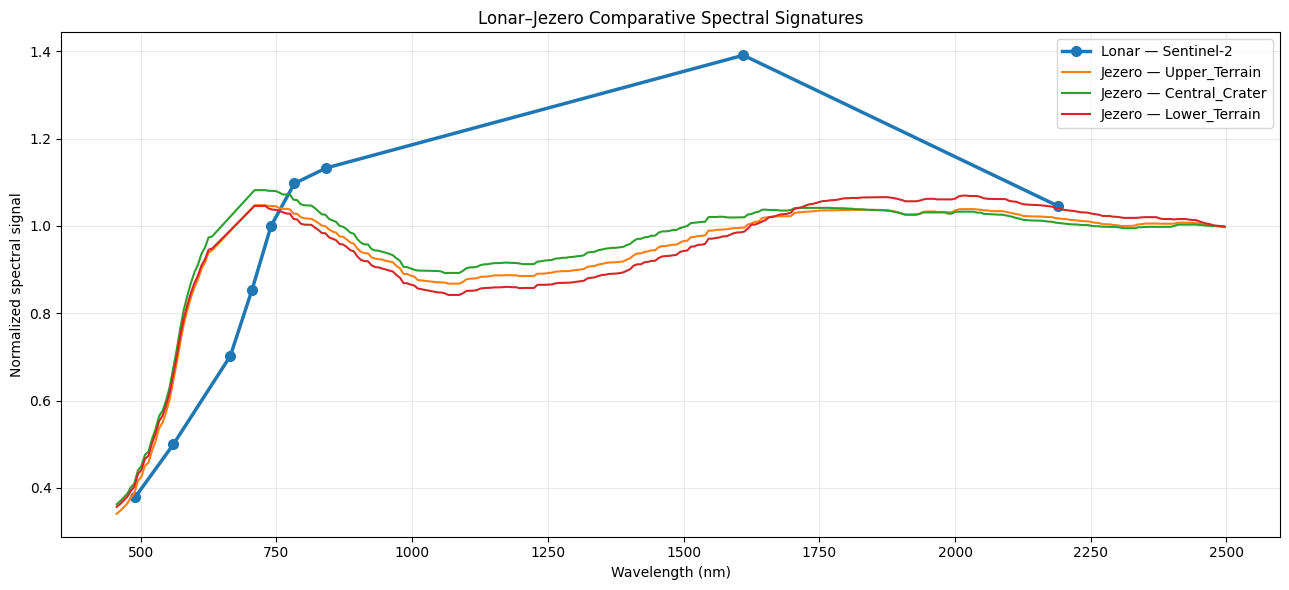

           ROI  Sentinel_Wavelength_nm  CRISM_Nearest_Wavelength_nm  Lonar_Normalized  Jezero_Normalized
 Upper_Terrain                     490                       488.17            0.3793             0.3875
 Upper_Terrain                     560                       559.78            0.4996             0.6448
 Upper_Terrain                     665                       631.44            0.7021             0.9442
 Upper_Terrain                     705                       709.68            0.8538             1.0473
 Upper_Terrain                     740                       742.30            1.0000             1.0455
 Upper_Terrain                     783                       781.45            1.0973             1.0281
 Upper_Terrain                     842                       840.22            1.1328             0.9991
 Upper_Terrain                    1610                      1611.84            1.3909             0.9960
 Upper_Terrain                    2190                 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Lonar data
lonar_wl = lonar_df["Wavelength_nm"].values
lonar_ref = lonar_df["Lonar_Median_Reflectance"].values

# Normalize Lonar spectral shape
lonar_norm = lonar_ref / np.nanmedian(lonar_ref)

plt.figure(figsize=(13, 6))

plt.plot(
    lonar_wl, lonar_norm,
    "o-", linewidth=2.5, markersize=7,
    label="Lonar — Sentinel-2"
)

comparison_rows = []

for name, spectrum in roi_spectra_clean.items():

    spectrum = np.asarray(spectrum, dtype=float)

    # Restrict to useful common spectral region
    mask = (
        np.isfinite(spectrum) &
        (spectrum > 0) &
        (wavelengths >= 450) &
        (wavelengths <= 2500)
    )

    x = wavelengths[mask]
    y = spectrum[mask]

    # Remove isolated spikes using rolling median
    y_clean = (
        pd.Series(y)
        .rolling(7, center=True, min_periods=1)
        .median()
        .values
    )

    y_norm = y_clean / np.nanmedian(y_clean)

    plt.plot(x, y_norm, linewidth=1.5, label=f"Jezero — {name}")

    # Nearest CRISM measurements to Sentinel-2 wavelengths
    for wl, lonar_value in zip(lonar_wl, lonar_norm):
        idx = np.argmin(np.abs(x - wl))

        comparison_rows.append({
            "ROI": name,
            "Sentinel_Wavelength_nm": wl,
            "CRISM_Nearest_Wavelength_nm": x[idx],
            "Lonar_Normalized": lonar_value,
            "Jezero_Normalized": y_norm[idx]
        })

plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalized spectral signal")
plt.title("Lonar–Jezero Comparative Spectral Signatures")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("Final_Lonar_Jezero_Comparison.png", dpi=300)
plt.show()

comparison_table = pd.DataFrame(comparison_rows)
print(comparison_table.round(4).to_string(index=False))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from google.colab import files

final_dir = Path("/content/Final_Lonar_Jezero_Project")
final_dir.mkdir(exist_ok=True)

# 1. Comparative spectral data
comparison_table.to_csv(
    final_dir / "Lonar_Jezero_Comparative_Spectra.csv",
    index=False
)

# 2. Jezero SAM similarity matrix
jezero_matrix.to_csv(
    final_dir / "Jezero_SAM_Similarity_Matrix.csv"
)

# 3. Jezero ROI reference matching
sam_results.to_csv(
    final_dir / "Jezero_ROI_SAM_Results.csv",
    index=False
)

# 4. Jezero classification statistics
class_counts.to_csv(
    final_dir / "Jezero_Mineral_Class_Statistics.csv",
    index=False
)

# 5. Final integrated numerical summary
summary = pd.DataFrame({
    "Parameter": [
        "Lonar sensor",
        "Jezero sensor",
        "Lonar spectral bands",
        "Jezero spectral bands",
        "Lonar leading reference match",
        "Jezero leading reference match",
        "Jezero mapped pixels",
        "Jezero dominant reference percentage"
    ],
    "Result": [
        "Sentinel-2 L2A",
        "CRISM MTRDR",
        9,
        489,
        "Nontronite",
        "Goethite + Quartz",
        int(np.sum(best_class > 0)),
        round(100 * np.sum(best_class == 1) / max(1, np.sum(best_class > 0)), 2)
    ]
})

summary.to_csv(final_dir / "Integrated_Project_Summary.csv", index=False)

# 6. Save final Jezero classification map
plt.figure(figsize=(10, 7))
plt.imshow(best_class, cmap="tab10", interpolation="nearest")
plt.title("Jezero CRISM Candidate Mineral Classification")
plt.axis("off")
plt.tight_layout()
plt.savefig(final_dir / "Jezero_Final_Mineral_Map.png", dpi=300)
plt.close()

# 7. Save final Jezero SAM matrix
plt.figure(figsize=(15, 5))
sns.heatmap(
    final_jezero_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis_r"
)
plt.title("Jezero CRISM SAM Similarity Matrix")
plt.tight_layout()
plt.savefig(final_dir / "Jezero_Final_SAM_Matrix.png", dpi=300)
plt.close()

# 8. Package final results
zip_path = "/content/Final_Lonar_Jezero_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in final_dir.iterdir():
        z.write(p, arcname=p.name)

print("FINAL INTEGRATED EXPORT COMPLETED")
display(summary)
files.download(zip_path)

FINAL INTEGRATED EXPORT COMPLETED


,Parameter,Result
0,Lonar sensor,Sentinel-2 L2A
1,Jezero sensor,CRISM MTRDR
2,Lonar spectral bands,9
3,Jezero spectral bands,489
4,Lonar leading reference match,Nontronite
5,Jezero leading reference match,Goethite + Quartz
6,Jezero mapped pixels,220978
7,Jezero dominant reference percentage,96.83


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

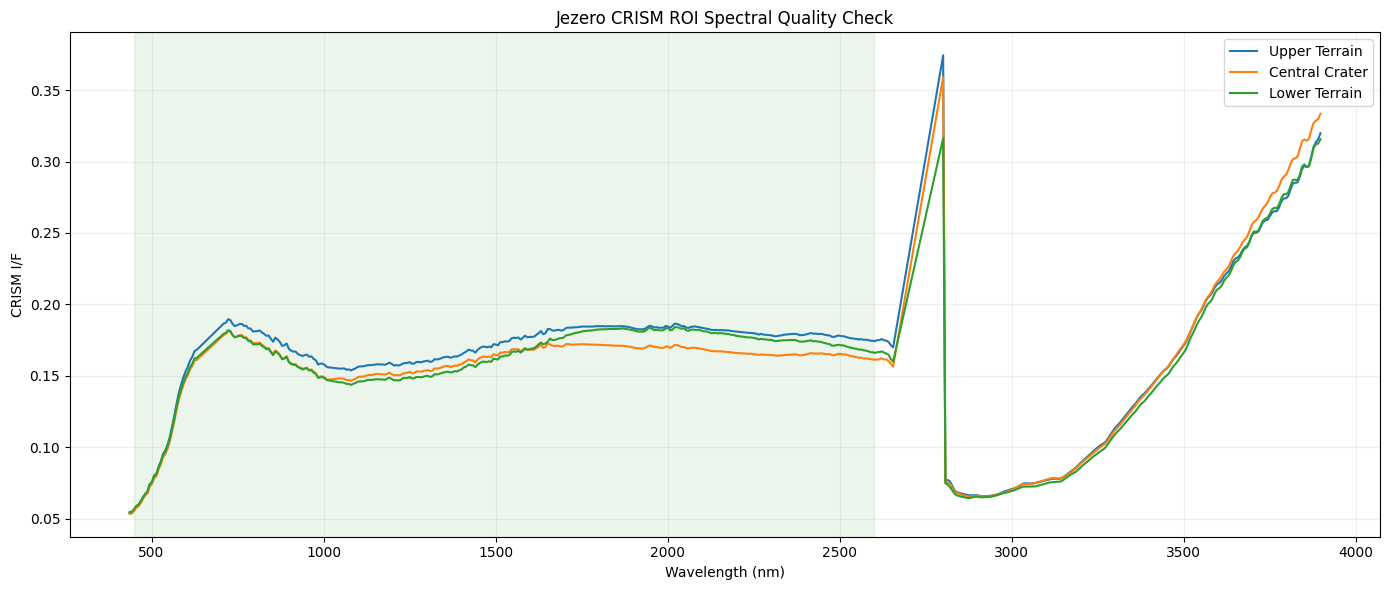

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(wavelengths, roi_spectra_clean["Upper_Terrain"], label="Upper Terrain")
plt.plot(wavelengths, roi_spectra_clean["Central_Crater"], label="Central Crater")
plt.plot(wavelengths, roi_spectra_clean["Lower_Terrain"], label="Lower Terrain")

plt.axvspan(450, 2600, alpha=0.08, color="green")

plt.xlabel("Wavelength (nm)")
plt.ylabel("CRISM I/F")
plt.title("Jezero CRISM ROI Spectral Quality Check")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [38]:

import numpy as np
import pandas as pd

quality_results = []

for roi_name, spectrum in roi_spectra_clean.items():
    spectrum = np.asarray(spectrum, dtype=float)

    mask = (
        (wavelengths >= 450) &
        (wavelengths <= 2600)
    )

    values = spectrum[mask]
    valid = np.isfinite(values)

    valid_values = values[valid]

    quality_results.append({
        "ROI": roi_name,
        "Total_Bands": len(values),
        "Valid_Bands": int(valid.sum()),
        "Invalid_Bands": int((~valid).sum()),
        "Minimum_IF": np.nanmin(values),
        "Maximum_IF": np.nanmax(values),
        "Median_IF": np.nanmedian(values)
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df.round(4))


,ROI,Total_Bands,Valid_Bands,Invalid_Bands,Minimum_IF,Maximum_IF,Median_IF
0,Upper_Terrain,311,311,0,0.0585,0.1897,0.1777
1,Central_Crater,311,311,0,0.0578,0.1815,0.1650
2,Lower_Terrain,311,311,0,0.0590,0.1841,0.1702


In [39]:

import numpy as np
import pandas as pd

jump_results = []

for roi_name, spectrum in roi_spectra_clean.items():
    mask = (wavelengths >= 450) & (wavelengths <= 2600)

    wl = wavelengths[mask]
    values = np.asarray(spectrum, dtype=float)[mask]

    valid = np.isfinite(values)

    differences = np.abs(np.diff(values))
    valid_pairs = valid[:-1] & valid[1:]

    differences[~valid_pairs] = np.nan

    median_jump = np.nanmedian(differences)
    threshold = median_jump * 5

    indices = np.where(differences > threshold)[0]

    for i in indices:
        jump_results.append({
            "ROI": roi_name,
            "Wavelength_nm": round(float(wl[i + 1]), 2),
            "Reflectance_Change": round(float(differences[i]), 4)
        })

jump_df = pd.DataFrame(jump_results)

if len(jump_df) > 0:
    display(jump_df)
else:
    print("No unusually large spectral jumps detected.")


,ROI,Wavelength_nm,Reflectance_Change
0,Upper_Terrain,468.65,0.0024
1,Upper_Terrain,475.16,0.0029
2,Upper_Terrain,481.67,0.0024
3,Upper_Terrain,494.68,0.0051
4,Upper_Terrain,507.70,0.0045
...,...,...,...
98,Lower_Terrain,735.77,0.0028
99,Lower_Terrain,859.81,0.0026
100,Lower_Terrain,879.41,0.0027
101,Lower_Terrain,899.02,0.0037


In [40]:

top_matches = (
    sam_results
    .sort_values("SAM_Angle")
    .groupby("ROI")
    .head(5)
    [["ROI", "Reference", "SAM_Angle", "Common_Bands"]]
    .reset_index(drop=True)
)

display(top_matches.round(4))


,ROI,Reference,SAM_Angle,Common_Bands
0,Upper_Terrain,Goethite0.02+Quartz_GDS240_BECKa,4.4957,311
1,Central_Crater,Goethite0.02+Quartz_GDS240_BECKa,4.5741,311
2,Lower_Terrain,Goethite0.02+Quartz_GDS240_BECKa,4.8359,311
3,Central_Crater,Goethite_Thin_Film_WS222_BECKa,6.0195,175
4,Upper_Terrain,Goethite_Thin_Film_WS222_BECKa,6.1054,175
5,Lower_Terrain,Diopside_HS15.1B_pyroxene_ASDFRc,6.2515,296
6,Central_Crater,Albite_HS143.1B_Plagioclase_ASDFRb,6.3486,296
7,Central_Crater,Albite_HS143.4B_Plagioclase_ASDFRc,6.3660,296
8,Central_Crater,Albite_HS66.1B_Plagioclase_ASDFRc,6.3661,296
9,Upper_Terrain,Diopside_HS15.1B_pyroxene_ASDFRc,6.5525,296


In [41]:

import numpy as np
import pandas as pd
from pathlib import Path

# Select top 5 existing matches from each ROI
candidates = (
    sam_results.sort_values("SAM_Angle")
    .groupby("ROI")
    .head(5)["Reference"]
    .unique()
    .tolist()
)

# Load matching reference spectra
ref_data = {}

for name in candidates:
    matches = [p for p in aref_files if name in Path(p).name]

    if matches:
        ref_data[name] = np.loadtxt(matches[0], skiprows=1).flatten()

# Build one common wavelength mask
common_mask = (
    (wavelengths >= 450) &
    (wavelengths <= 2600)
)

for roi in ["Upper_Terrain", "Central_Crater", "Lower_Terrain"]:
    common_mask &= np.isfinite(roi_spectra_clean[roi])

for spectrum in ref_data.values():
    common_mask &= np.isfinite(spectrum)

print("Common valid bands:", int(common_mask.sum()))

# Calculate SAM using identical bands
results = []

for roi in ["Upper_Terrain", "Central_Crater", "Lower_Terrain"]:
    sample = np.asarray(roi_spectra_clean[roi])[common_mask]

    for name, reference in ref_data.items():
        ref = reference[common_mask]

        cosine = np.dot(sample, ref) / (
            np.linalg.norm(sample) * np.linalg.norm(ref)
        )

        angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

        results.append({
            "ROI": roi,
            "Reference": name,
            "SAM_Angle": angle,
            "Common_Bands": int(common_mask.sum())
        })

equal_band_results = pd.DataFrame(results)

display(
    equal_band_results.sort_values(
        ["ROI", "SAM_Angle"]
    ).groupby("ROI").head(5).round(4)
)


Common valid bands: 311


,ROI,Reference,SAM_Angle,Common_Bands
6,Central_Crater,Goethite0.02+Quartz_GDS240_BECKa,4.5741,311
8,Central_Crater,Diopside_HS15.1B_pyroxene_ASDFRc,102.9297,311
9,Central_Crater,Albite_HS143.1B_Plagioclase_ASDFRb,102.9297,311
10,Central_Crater,Albite_HS143.4B_Plagioclase_ASDFRc,102.9297,311
11,Central_Crater,Albite_HS66.1B_Plagioclase_ASDFRc,102.9297,311
12,Lower_Terrain,Goethite0.02+Quartz_GDS240_BECKa,4.8359,311
14,Lower_Terrain,Diopside_HS15.1B_pyroxene_ASDFRc,103.0416,311
15,Lower_Terrain,Albite_HS143.1B_Plagioclase_ASDFRb,103.0416,311
16,Lower_Terrain,Albite_HS143.4B_Plagioclase_ASDFRc,103.0416,311
17,Lower_Terrain,Albite_HS66.1B_Plagioclase_ASDFRc,103.0416,311


In [42]:

import numpy as np
import pandas as pd

valid_range = (-5, 5)

common_mask = (
    (wavelengths >= 450) &
    (wavelengths <= 2600)
)

# Require valid values in all three ROI spectra
for roi in ["Upper_Terrain", "Central_Crater", "Lower_Terrain"]:
    values = np.asarray(roi_spectra_clean[roi], dtype=float)
    common_mask &= np.isfinite(values) & (values > -5) & (values < 5)

# Require valid values in all reference spectra
for spectrum in ref_data.values():
    values = np.asarray(spectrum, dtype=float)
    common_mask &= np.isfinite(values) & (values > -5) & (values < 5)

print("Valid common bands:", int(common_mask.sum()))

results = []

for roi in ["Upper_Terrain", "Central_Crater", "Lower_Terrain"]:
    sample = np.asarray(roi_spectra_clean[roi], dtype=float)[common_mask]

    for name, reference in ref_data.items():
        ref = np.asarray(reference, dtype=float)[common_mask]

        denominator = np.linalg.norm(sample) * np.linalg.norm(ref)

        if denominator == 0:
            continue

        cosine = np.dot(sample, ref) / denominator
        angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

        results.append({
            "ROI": roi,
            "Reference": name,
            "SAM_Angle": angle,
            "Common_Bands": int(common_mask.sum())
        })

corrected_results = pd.DataFrame(results)

display(
    corrected_results.sort_values(
        ["ROI", "SAM_Angle"]
    ).groupby("ROI").head(5).round(4)
)


Valid common bands: 175


,ROI,Reference,SAM_Angle,Common_Bands
7,Central_Crater,Goethite_Thin_Film_WS222_BECKa,6.0195,175
6,Central_Crater,Goethite0.02+Quartz_GDS240_BECKa,6.1683,175
10,Central_Crater,Albite_HS143.4B_Plagioclase_ASDFRc,7.7452,175
11,Central_Crater,Albite_HS66.1B_Plagioclase_ASDFRc,8.1190,175
9,Central_Crater,Albite_HS143.1B_Plagioclase_ASDFRb,8.1501,175
12,Lower_Terrain,Goethite0.02+Quartz_GDS240_BECKa,6.6510,175
13,Lower_Terrain,Goethite_Thin_Film_WS222_BECKa,6.7413,175
16,Lower_Terrain,Albite_HS143.4B_Plagioclase_ASDFRc,7.6051,175
17,Lower_Terrain,Albite_HS66.1B_Plagioclase_ASDFRc,8.1112,175
15,Lower_Terrain,Albite_HS143.1B_Plagioclase_ASDFRb,8.1371,175


In [43]:
corrected_results.to_csv(
    "/content/Jezero_Equal_Band_Validation.csv",
    index=False
)

print("Validation results saved successfully.")

Validation results saved successfully.


In [45]:
import zipfile
from pathlib import Path

zip_path = Path("/content/Final_Lonar_Jezero_Project.zip")
validation_file = Path("/content/Jezero_Equal_Band_Validation.csv")

with zipfile.ZipFile(zip_path, "a", zipfile.ZIP_DEFLATED) as z:
    z.write(validation_file, arcname=validation_file.name)

print("Updated project archive successfully!")
print("Archive size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

Updated project archive successfully!
Archive size: 0.39 MB


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'Jezero_Equal_Band_Validation.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
